
This notebook demonstrates the **Model-Wise Double Descent** curve on a synthetic noisy regression dataset using a **1-hidden-layer ReLU neural network** whose hidden width (complexity) increases past the interpolation threshold.

### 1. Import Libraries
Load NumPy for matrix computations and Matplotlib for plotting the error curves.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)

### 2. Generate Dataset with Label Noise
Create $N = 30$ noisy training samples and $500$ clean test samples in $d = 10$ dimensions (label noise makes the interpolation spike clearly visible, as highlighted in the 2020 paper).

In [8]:
N_train = 30
d = 10

X_train = np.random.randn(N_train, d)
true_w = np.random.randn(d, 1) / np.sqrt(d)
y_train = X_train @ true_w + np.random.normal(0, 0.5, size=(N_train, 1))

X_test = np.random.randn(500, d)
y_test = X_test @ true_w

### 3. Define 1-Hidden-Layer Neural Network & Sweep Complexity
Build a 1-hidden-layer ReLU network $f(x) = \text{ReLU}(xW_1 + b_1)W_2$ and increase hidden layer width $H$ from $2$ to $800$, solving for $W_2$ via the minimum-norm pseudoinverse (the exact convergence point of gradient descent from zero initialization).

In [9]:
widths = [2, 5, 10, 15, 20, 25, 28, 30, 32, 35, 45, 60, 100, 200, 400, 800]
max_w = max(widths)

W1_full = np.random.randn(d, max_w) / np.sqrt(d)
b1_full = np.random.randn(1, max_w) * 0.5

train_errors = []
test_errors = []

for h in widths:
    H_train = np.maximum(0, X_train @ W1_full[:, :h] + b1_full[:, :h])
    H_test = np.maximum(0, X_test @ W1_full[:, :h] + b1_full[:, :h])
    
    W2 = np.linalg.pinv(H_train, rcond=1e-10) @ y_train
    
    train_errors.append(np.mean((H_train @ W2 - y_train) ** 2))
    test_errors.append(np.mean((H_test @ W2 - y_test) ** 2))

### 4. Plot the Double Descent Curve
Visualize training and test MSE across hidden widths to observe the classical U-shaped regime ($H < 30$), the interpolation peak ($H = 30$), and the modern overparameterized descent ($H > 30$).

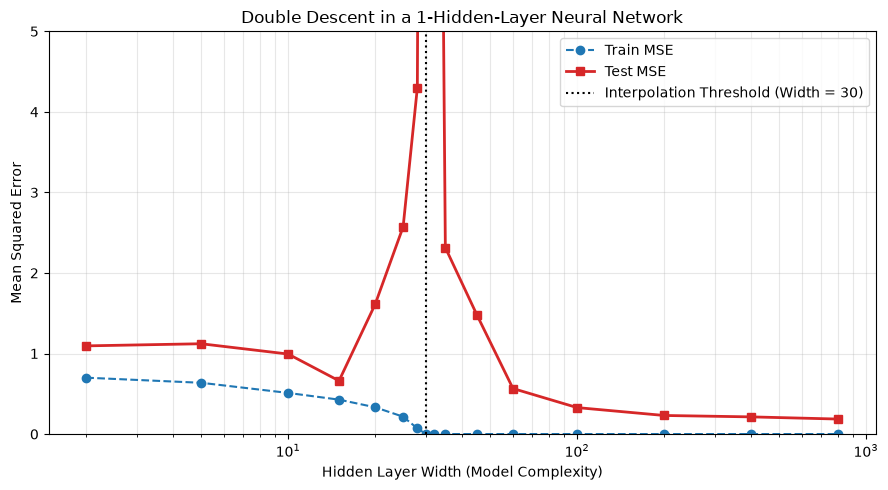

In [16]:
plt.figure(figsize=(9, 5))
plt.plot(widths, train_errors, 'o--', label='Train MSE', color='#1f77b4')
plt.plot(widths, test_errors, 's-', label='Test MSE', color='#d62728', linewidth=2)
plt.axvline(N_train, color='black', linestyle=':', label=f'Interpolation Threshold (Width = {N_train})')

plt.xscale('log')
plt.ylim(0, 5)

plt.xlabel('Hidden Layer Width (Model Complexity)')
plt.ylabel('Mean Squared Error')
plt.title('Double Descent in a 1-Hidden-Layer Neural Network')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()